# 02 — Monte Carlo Simulation

## Objective

The purpose of this notebook is to extend the deterministic MEMS model into an uncertainty-aware simulation framework using Monte Carlo analysis.

Instead of using one fixed set of physical and sensor parameters, uncertain quantities will be represented by probability distributions. Repeated random samples will then be drawn from these distributions and used to generate many simulated experiments.

The Monte Carlo workflow is

$$
\text{uncertain parameters}
\rightarrow
\text{random sampling}
\rightarrow
\text{repeated MEMS simulations}
\rightarrow
\text{distribution of system responses}.
$$

The uncertain variables considered in this study include physical parameters such as mass, damping, stiffness, and nonlinear stiffness, as well as sensor and environmental quantities.

The initial objectives are to:

1. define the uncertainty distributions,
2. generate reproducible random parameter samples,
3. validate that the generated samples satisfy the specified physical bounds,
4. run repeated MEMS simulations,
5. store summary quantities from every simulation, and
6. examine how uncertainty propagates into the system response.

This notebook provides the Monte Carlo dataset that will later support uncertainty quantification, system identification, equation discovery, machine learning, and robustness analysis.

In [1]:
# IMPORT REQUIRED PACKAGES AND PROJECT MODULES

from pathlib import Path
import sys

# The notebook is stored inside the "notebooks" folder,
# while the project source code is one folder above.
PROJECT_ROOT = Path.cwd().parent

# Add the project root to Python's search path so that
# modules inside src/ can be imported.
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))


# Standard scientific Python packages.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


from src.utils import (
    load_yaml_config,
    config_path,
    data_path,
    results_path,
    figures_path,
    ensure_directory,
)


# Monte Carlo uncertainty functions that we just created.
from src.uncertainty import (
    sample_bounded_normal,
    sample_uniform,
    sample_from_distribution,
    generate_monte_carlo_samples,
)


from src.dynamics import MEMSParameters
from src.excitation import chirp_excitation
from src.sensors import SensorParameters
from src.simulation import simulate_mems_system

In [2]:
# LOAD THE MONTE CARLO CONFIGURATION

# Load the YAML file that contains:
#
# - the number of Monte Carlo simulations,
# - the random seed,
# - the probability distributions,
# - the lower and upper physical bounds,
# - the convergence-study sample sizes.
#
# Keeping these values in a configuration file makes the
# Monte Carlo experiment reproducible and easy to modify.

monte_carlo_config = load_yaml_config(
    config_path("monte_carlo_config.yaml")
)


# Display the full configuration so that we can inspect
# exactly which uncertainty assumptions are currently defined.
monte_carlo_config

{'monte_carlo': {'seed': 9512,
  'number_of_simulations': 1000,
  'save_individual_time_series': False,
  'convergence_check': {'enabled': True,
   'sample_sizes': [100, 250, 500, 1000]}},
 'uncertain_parameters': {'mass': {'distribution': 'normal',
   'mean': 1.0,
   'standard_deviation': 0.03,
   'minimum': 0.85,
   'maximum': 1.15},
  'damping': {'distribution': 'normal',
   'mean': 0.08,
   'standard_deviation': 0.008,
   'minimum': 0.04,
   'maximum': 0.12},
  'stiffness': {'distribution': 'normal',
   'mean': 1000.0,
   'standard_deviation': 50.0,
   'minimum': 800.0,
   'maximum': 1200.0},
  'nonlinear_stiffness': {'distribution': 'uniform',
   'minimum': 0.0,
   'maximum': 50.0},
  'temperature': {'distribution': 'uniform',
   'minimum': -20.0,
   'maximum': 80.0}},
 'measurement_uncertainty': {'noise_standard_deviation': {'distribution': 'uniform',
   'minimum': 0.0,
   'maximum': 0.05},
  'sensor_gain': {'distribution': 'normal',
   'mean': 1.0,
   'standard_deviation': 0.01,

In [3]:
# INSPECT THE MONTE CARLO EXPERIMENT SETTINGS


monte_carlo_settings = monte_carlo_config["monte_carlo"]
uncertain_parameters = monte_carlo_config["uncertain_parameters"]


print("Monte Carlo settings:")
print(
    f"  Number of simulations: "
    f"{monte_carlo_settings['number_of_simulations']}"
)
print(
    f"  Random seed: "
    f"{monte_carlo_settings['seed']}"
)
print(
    f"  Save individual time series: "
    f"{monte_carlo_settings['save_individual_time_series']}"
)

print()
print("Convergence sample sizes:")
print(
    monte_carlo_settings["convergence_check"]["sample_sizes"]
)

print()
print("Uncertain parameters:")

for parameter_name in uncertain_parameters:
    print(f"  - {parameter_name}")

Monte Carlo settings:
  Number of simulations: 1000
  Random seed: 9512
  Save individual time series: False

Convergence sample sizes:
[100, 250, 500, 1000]

Uncertain parameters:
  - mass
  - damping
  - stiffness
  - nonlinear_stiffness
  - temperature


In [4]:
# INSPECT THE MONTE CARLO CONFIGURATION SECTIONS


# Print the names of the top-level sections contained in
# monte_carlo_config.yaml.
#
# This helps us understand how physical, environmental,
# and sensor uncertainty are organised before sampling them.

print("Top-level configuration sections:")

for section_name in monte_carlo_config.keys():
    print(f"  - {section_name}")


# Print the variables currently stored specifically inside
# the uncertain_parameters section.

print()
print("Variables inside uncertain_parameters:")

for parameter_name in uncertain_parameters.keys():
    print(f"  - {parameter_name}")

Top-level configuration sections:
  - monte_carlo
  - uncertain_parameters
  - measurement_uncertainty

Variables inside uncertain_parameters:
  - mass
  - damping
  - stiffness
  - nonlinear_stiffness
  - temperature


In [5]:
# INSPECT THE MEASUREMENT UNCERTAINTY SETTINGS

# Extract the measurement-uncertainty section from the
# Monte Carlo configuration.
measurement_uncertainty = monte_carlo_config[
    "measurement_uncertainty"
]


# Print the variables that describe uncertainty in the
# simulated sensor measurements.
print("Measurement uncertainty variables:")

for parameter_name in measurement_uncertainty.keys():
    print(f"  - {parameter_name}")

Measurement uncertainty variables:
  - noise_standard_deviation
  - sensor_gain
  - sensor_bias


In [6]:
# ------------------------------------------------------------
# GENERATE MONTE CARLO PARAMETER SAMPLES
# ------------------------------------------------------------

# Read the number of simulations and random seed from
# the Monte Carlo configuration.
number_of_simulations = (
    monte_carlo_settings["number_of_simulations"]
)

monte_carlo_seed = monte_carlo_settings["seed"]


# Create a reproducible NumPy random-number generator.
#
# Using the same seed means that the same random parameter
# samples can be generated again later.
rng = np.random.default_rng(
    monte_carlo_seed
)


# Generate all uncertain physical, environmental,
# and measurement parameters.
monte_carlo_samples = generate_monte_carlo_samples(
    rng=rng,
    uncertain_parameters=uncertain_parameters,
    measurement_uncertainty=measurement_uncertainty,
    number_of_simulations=number_of_simulations,
)


# Display the names of the generated parameter arrays.
print("Generated Monte Carlo parameters:")

for parameter_name in monte_carlo_samples.keys():
    print(f"  - {parameter_name}")

Generated Monte Carlo parameters:
  - mass
  - damping
  - stiffness
  - nonlinear_stiffness
  - temperature
  - noise_standard_deviation
  - sensor_gain
  - sensor_bias


In [7]:
# CREATE THE MONTE CARLO PARAMETER TABLE

# Convert the dictionary of sampled parameter arrays into
# a pandas DataFrame.
#
# Each row represents one Monte Carlo simulation.
# Each column represents one uncertain parameter.

monte_carlo_parameter_data = pd.DataFrame(
    monte_carlo_samples
)


# Add an explicit simulation ID so that every Monte Carlo
# experiment can be uniquely identified later.
monte_carlo_parameter_data.insert(
    0,
    "simulation_id",
    np.arange(1, number_of_simulations + 1)
)


# Display the first five Monte Carlo parameter sets.
monte_carlo_parameter_data.head()

,simulation_id,mass,damping,stiffness,nonlinear_stiffness,temperature,noise_standard_deviation,sensor_gain,sensor_bias
0,1,1.039614,0.089726,1040.916993,49.946578,49.435194,0.035200,1.002202,-0.003551
1,2,0.970665,0.066558,955.352019,36.428691,7.789487,0.012372,1.002399,-0.010228
2,3,0.983404,0.086589,981.427172,16.351664,16.193005,0.041818,1.009968,0.021555
3,4,0.971510,0.077894,1050.033627,38.994851,29.921635,0.001968,1.001104,0.004464
4,5,1.027866,0.086712,1050.164251,26.344022,33.011952,0.046712,1.029676,0.006173


In [8]:
# VALIDATE THE MONTE CARLO PARAMETER SAMPLES


# Check the overall shape of the Monte Carlo parameter table.
print(
    f"Monte Carlo parameter table shape: "
    f"{monte_carlo_parameter_data.shape}"
)


# Check whether any missing values are present.
print()
print("Missing values:")

print(
    monte_carlo_parameter_data.isna().sum()
)



# CHECK PHYSICAL AND ENVIRONMENTAL PARAMETER BOUNDS


print()
print("Physical/environmental parameter bounds:")

for parameter_name, parameter_config in (
    uncertain_parameters.items()
):

    sampled_minimum = (
        monte_carlo_parameter_data[parameter_name].min()
    )

    sampled_maximum = (
        monte_carlo_parameter_data[parameter_name].max()
    )

    configured_minimum = parameter_config["minimum"]
    configured_maximum = parameter_config["maximum"]

    within_bounds = (
        sampled_minimum >= configured_minimum
        and sampled_maximum <= configured_maximum
    )

    print(
        f"{parameter_name}: "
        f"sampled range = "
        f"[{sampled_minimum:.6f}, "
        f"{sampled_maximum:.6f}], "
        f"within bounds = {within_bounds}"
    )



# CHECK MEASUREMENT PARAMETER BOUNDS

print()
print("Measurement parameter bounds:")

for parameter_name, parameter_config in (
    measurement_uncertainty.items()
):

    sampled_minimum = (
        monte_carlo_parameter_data[parameter_name].min()
    )

    sampled_maximum = (
        monte_carlo_parameter_data[parameter_name].max()
    )

    configured_minimum = parameter_config["minimum"]
    configured_maximum = parameter_config["maximum"]

    within_bounds = (
        sampled_minimum >= configured_minimum
        and sampled_maximum <= configured_maximum
    )

    print(
        f"{parameter_name}: "
        f"sampled range = "
        f"[{sampled_minimum:.6f}, "
        f"{sampled_maximum:.6f}], "
        f"within bounds = {within_bounds}"
    )

Monte Carlo parameter table shape: (1000, 9)

Missing values:
simulation_id               0
mass                        0
damping                     0
stiffness                   0
nonlinear_stiffness         0
temperature                 0
noise_standard_deviation    0
sensor_gain                 0
sensor_bias                 0
dtype: int64

Physical/environmental parameter bounds:
mass: sampled range = [0.892943, 1.095593], within bounds = True
damping: sampled range = [0.054582, 0.107656], within bounds = True
stiffness: sampled range = [823.159683, 1144.483738], within bounds = True
nonlinear_stiffness: sampled range = [0.053956, 49.946578], within bounds = True
temperature: sampled range = [-19.996462, 79.946778], within bounds = True

Measurement parameter bounds:
noise_standard_deviation: sampled range = [0.000084, 0.049871], within bounds = True
sensor_gain: sampled range = [0.970343, 1.033849], within bounds = True
sensor_bias: sampled range = [-0.031923, 0.031614], within bo

## Validation of Monte Carlo Parameter Sampling

A total of $1000$ Monte Carlo parameter sets were generated successfully.

The resulting parameter table contains one simulation identifier and eight uncertain physical, environmental, and measurement variables. No missing values were detected.

All generated samples satisfy their specified lower and upper bounds. The normally distributed parameters remain concentrated around their configured mean values, whereas uniformly distributed parameters explore their allowed intervals more broadly.

The successful validation of the sampled parameter sets confirms that the uncertainty-generation stage is functioning correctly. These parameter combinations can therefore be used as inputs to the repeated MEMS simulations.

In [9]:
# LOAD THE BASE SIMULATION CONFIGURATION

base_config = load_yaml_config(
    config_path("base_config.yaml")
)

simulation_config = base_config["simulation"]
excitation_config = base_config["excitation"]
initial_conditions = base_config["initial_conditions"]
sensor_config = base_config["sensor"]

In [10]:
# TEST ONE MONTE CARLO SIMULATION


# Select the first Monte Carlo parameter set.
#
# iloc[0] means:
# take the first row of the DataFrame.
first_sample = monte_carlo_parameter_data.iloc[0]



# CREATE THE PHYSICAL SYSTEM

# Build a MEMSParameters object using the sampled physical
# parameters from Monte Carlo simulation 1.

mc_parameters = MEMSParameters(
    mass=first_sample["mass"],
    damping=first_sample["damping"],
    stiffness=first_sample["stiffness"],
    nonlinear_stiffness=first_sample[
        "nonlinear_stiffness"
    ],
)

mc_parameters.validate()



# CREATE THE SENSOR MODEL

# Build the sensor model using the sampled measurement
# uncertainty values from the same Monte Carlo row.

mc_sensor_parameters = SensorParameters(
    gain=first_sample["sensor_gain"],
    bias=first_sample["sensor_bias"],
    noise_standard_deviation=first_sample[
        "noise_standard_deviation"
    ],
)

mc_sensor_parameters.validate()



# CREATE THE CHIRP EXCITATION

simulation_duration = (
    simulation_config["end_time"]
    - simulation_config["start_time"]
)

mc_excitation = chirp_excitation(
    amplitude=excitation_config["amplitude"],
    start_frequency=excitation_config["start_frequency"],
    end_frequency=excitation_config["end_frequency"],
    duration=simulation_duration,
)



# RUN THE SIMULATION

mc_test_result = simulate_mems_system(
    parameters=mc_parameters,
    excitation_function=mc_excitation,

    start_time=simulation_config["start_time"],
    end_time=simulation_config["end_time"],
    sampling_frequency=simulation_config[
        "sampling_frequency"
    ],

    initial_displacement=initial_conditions[
        "displacement"
    ],
    initial_velocity=initial_conditions[
        "velocity"
    ],

    sensor_parameters=mc_sensor_parameters,
    sensor_output=sensor_config["output"],

    solver_method=simulation_config["solver"]["method"],
    rtol=simulation_config["solver"]["rtol"],
    atol=simulation_config["solver"]["atol"],

    random_seed=int(first_sample["simulation_id"]),
)


# Display a compact summary instead of printing
# all 20,001 values.

print("Monte Carlo simulation 1 completed.")
print()
print("Physical parameters:")
print(mc_parameters)

print()
print("Sensor parameters:")
print(mc_sensor_parameters)

print()
print(
    f"Number of simulated samples: "
    f"{len(mc_test_result.time)}"
)

Monte Carlo simulation 1 completed.

Physical parameters:
MEMSParameters(mass=np.float64(1.0396135178545343), damping=np.float64(0.08972633403124629), stiffness=np.float64(1040.9169925257486), nonlinear_stiffness=np.float64(49.9465784553349))

Sensor parameters:
SensorParameters(gain=np.float64(1.0022016476779554), bias=np.float64(-0.003551153641393408), noise_standard_deviation=np.float64(0.03519975987933646))

Number of simulated samples: 20001


In [11]:
# COMPARE TRUE AND MEASURED ACCELERATION


# Calculate the difference between the noisy measured signal
# and the true simulated acceleration.
measurement_error = (
    mc_test_result.measured_signal
    - mc_test_result.acceleration
)


# Calculate simple statistics describing the measurement error.
mean_measurement_error = np.mean(
    measurement_error
)

standard_deviation_measurement_error = np.std(
    measurement_error
)

maximum_absolute_measurement_error = np.max(
    np.abs(measurement_error)
)


print(
    f"Mean measurement error: "
    f"{mean_measurement_error:.6f}"
)

print(
    f"Measurement-error standard deviation: "
    f"{standard_deviation_measurement_error:.6f}"
)

print(
    f"Maximum absolute measurement error: "
    f"{maximum_absolute_measurement_error:.6f}"
)

Mean measurement error: -0.003829
Measurement-error standard deviation: 0.035463
Maximum absolute measurement error: 0.131944


### Validation of the Uncertain Sensor Model

For the first Monte Carlo realization, the simulated sensor contained gain error, bias, and Gaussian measurement noise.

The resulting mean measurement error was

$$
-0.003829,
$$

which is close to the sampled sensor bias of approximately

$$
-0.003551.
$$

The standard deviation of the measurement error was

$$
0.035463,
$$

which closely agrees with the sampled noise standard deviation of approximately

$$
0.035200.
$$

This agreement provides a numerical sanity check that the measurement-uncertainty model is behaving as expected. The measured signal is therefore no longer identical to the true acceleration, in contrast to the ideal-sensor baseline used in Notebook 01.

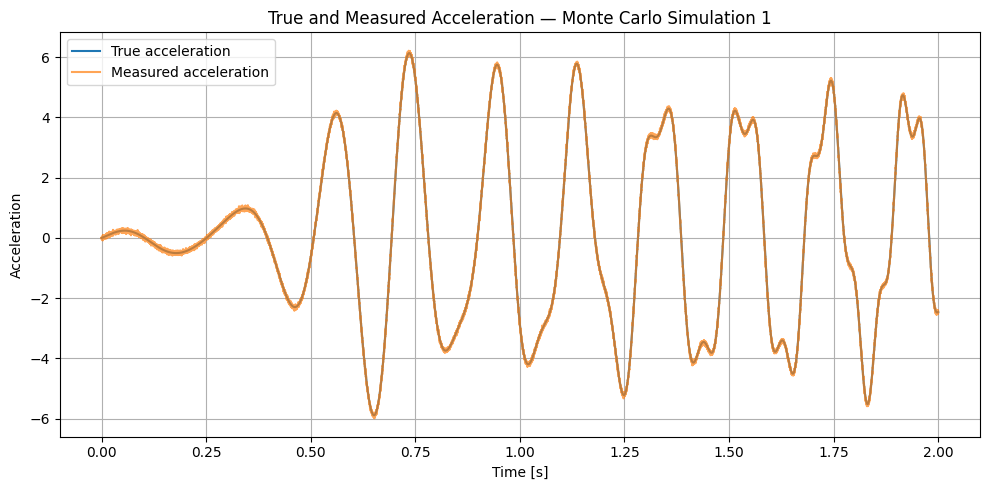

In [12]:
# COMPARE TRUE AND MEASURED ACCELERATION VISUALLY

# Plot the true physical acceleration.
plt.figure(figsize=(10, 5))

plt.plot(
    mc_test_result.time,
    mc_test_result.acceleration,
    label="True acceleration"
)


# Plot the signal reported by the uncertain sensor.
plt.plot(
    mc_test_result.time,
    mc_test_result.measured_signal,
    label="Measured acceleration",
    alpha=0.7
)


plt.xlabel("Time [s]")
plt.ylabel("Acceleration")
plt.title(
    "True and Measured Acceleration — Monte Carlo Simulation 1"
)

plt.legend()
plt.grid(True)
plt.tight_layout()

plt.show()

### True and Measured Acceleration

The measured acceleration closely follows the true simulated acceleration because the sampled gain error, bias, and measurement noise are small relative to the magnitude of the system response.

The two signals therefore overlap strongly in the time-domain plot. Small deviations are nevertheless present and were confirmed numerically through the non-zero measurement-error mean and standard deviation.

This shows that the simulated sensor preserves the main dynamical behaviour while introducing controlled measurement uncertainty.

In [ ]:
# RUN THE FULL MONTE CARLO SIMULATION STUDY

# Create an empty list in which we will store one summary
# dictionary for each Monte Carlo simulation.
monte_carlo_results = []


# Loop over all sampled parameter sets.
for row_index, sample in monte_carlo_parameter_data.iterrows():

    
    # CREATE THE PHYSICAL PARAMETER SET FOR THIS SIMULATION
    

    current_parameters = MEMSParameters(
        mass=sample["mass"],
        damping=sample["damping"],
        stiffness=sample["stiffness"],
        nonlinear_stiffness=sample[
            "nonlinear_stiffness"
        ],
    )

    current_parameters.validate()


    
    # CREATE THE SENSOR PARAMETER SET
    

    current_sensor = SensorParameters(
        gain=sample["sensor_gain"],
        bias=sample["sensor_bias"],
        noise_standard_deviation=sample[
            "noise_standard_deviation"
        ],
    )

    current_sensor.validate()


    
    # RUN THE DYNAMICAL SIMULATION
    

    current_result = simulate_mems_system(
        parameters=current_parameters,
        excitation_function=mc_excitation,

        start_time=simulation_config["start_time"],
        end_time=simulation_config["end_time"],
        sampling_frequency=simulation_config[
            "sampling_frequency"
        ],

        initial_displacement=initial_conditions[
            "displacement"
        ],
        initial_velocity=initial_conditions[
            "velocity"
        ],

        sensor_parameters=current_sensor,
        sensor_output=sensor_config["output"],

        solver_method=simulation_config["solver"]["method"],
        rtol=simulation_config["solver"]["rtol"],
        atol=simulation_config["solver"]["atol"],

        # Give every Monte Carlo run its own reproducible
        # sensor-noise realization.
        random_seed=int(sample["simulation_id"]),
    )


    
    # CALCULATE PHYSICAL SUMMARY QUANTITIES
    

    current_natural_frequency = (
        1.0
        / (2.0 * np.pi)
        * np.sqrt(
            sample["stiffness"]
            / sample["mass"]
        )
    )

    current_damping_ratio = (
        sample["damping"]
        / (
            2.0
            * np.sqrt(
                sample["stiffness"]
                * sample["mass"]
            )
        )
    )


    
    # CALCULATE RESPONSE SUMMARY QUANTITIES
    

    peak_displacement = np.max(
        np.abs(current_result.displacement)
    )

    peak_velocity = np.max(
        np.abs(current_result.velocity)
    )

    peak_acceleration = np.max(
        np.abs(current_result.acceleration)
    )

    peak_measured_signal = np.max(
        np.abs(current_result.measured_signal)
    )

    rms_acceleration = np.sqrt(
        np.mean(
            current_result.acceleration ** 2
        )
    )

    rms_measured_signal = np.sqrt(
        np.mean(
            current_result.measured_signal ** 2
        )
    )


    
    # STORE ONE SUMMARY ROW
    

    monte_carlo_results.append(
        {
            "simulation_id": int(
                sample["simulation_id"]
            ),

            "mass": sample["mass"],
            "damping": sample["damping"],
            "stiffness": sample["stiffness"],
            "nonlinear_stiffness": sample[
                "nonlinear_stiffness"
            ],
            "temperature": sample["temperature"],

            "noise_standard_deviation": sample[
                "noise_standard_deviation"
            ],
            "sensor_gain": sample["sensor_gain"],
            "sensor_bias": sample["sensor_bias"],

            "natural_frequency": (
                current_natural_frequency
            ),
            "damping_ratio": (
                current_damping_ratio
            ),

            "peak_displacement": (
                peak_displacement
            ),
            "peak_velocity": (
                peak_velocity
            ),
            "peak_acceleration": (
                peak_acceleration
            ),
            "peak_measured_signal": (
                peak_measured_signal
            ),

            "rms_acceleration": (
                rms_acceleration
            ),
            "rms_measured_signal": (
                rms_measured_signal
            ),
        }
    )


# Convert the list of dictionaries into a DataFrame.
monte_carlo_results_data = pd.DataFrame(
    monte_carlo_results
)


print(
    "Completed Monte Carlo simulations:",
    len(monte_carlo_results_data)
)

print(
    "Monte Carlo results shape:",
    monte_carlo_results_data.shape
)

In [ ]:
# INSPECT THE MONTE CARLO RESULTS


# Display the first five rows of the completed Monte Carlo
# results table.
#
# Each row now contains:
#
# - the uncertain input parameters,
# - derived physical properties,
# - summary quantities describing the simulated response.

monte_carlo_results_data.head()

,simulation_id,mass,damping,stiffness,nonlinear_stiffness,temperature,noise_standard_deviation,sensor_gain,sensor_bias,natural_frequency,damping_ratio,peak_displacement,peak_velocity,peak_acceleration,peak_measured_signal,rms_acceleration,rms_measured_signal
0,1,1.039614,0.089726,1040.916993,49.946578,49.435194,0.035200,1.002202,-0.003551,5.036075,0.001364,0.005246,0.180866,6.136700,6.215065,2.952372,2.958320
1,2,0.970665,0.066558,955.352019,36.428691,7.789487,0.012372,1.002399,-0.010228,4.993063,0.001093,0.005643,0.194743,6.463715,6.484976,3.171572,3.179025
2,3,0.983404,0.086589,981.427172,16.351664,16.193005,0.041818,1.009968,0.021555,5.027859,0.001394,0.005547,0.191309,6.464234,6.643617,3.116529,3.148509
3,4,0.971510,0.077894,1050.033627,38.994851,29.921635,0.001968,1.001104,0.004464,5.232365,0.001219,0.005514,0.188895,6.986508,7.001257,3.289924,3.293455
4,5,1.027866,0.086712,1050.164251,26.344022,33.011952,0.046712,1.029676,0.006173,5.087219,0.001320,0.005289,0.182024,6.330212,6.637474,3.012130,3.101969


In [ ]:
# VALIDATE THE MONTE CARLO RESULTS TABLE

# Check the overall size of the completed results table.
print(
    f"Results table shape: "
    f"{monte_carlo_results_data.shape}"
)


# Check for missing values.
print()
print("Missing values:")

print(
    monte_carlo_results_data.isna().sum()
)


# Check whether any infinite numerical values occurred.
#
# Infinite values could indicate numerical instability
# or a failed simulation.
numeric_data = monte_carlo_results_data.select_dtypes(
    include=[np.number]
)

number_of_infinite_values = np.isinf(
    numeric_data.to_numpy()
).sum()

print()
print(
    f"Number of infinite values: "
    f"{number_of_infinite_values}"
)


# Check that all important response quantities are positive.
#
# These quantities are defined as magnitudes or RMS values,
# so negative values would indicate an error.

response_columns = [
    "peak_displacement",
    "peak_velocity",
    "peak_acceleration",
    "peak_measured_signal",
    "rms_acceleration",
    "rms_measured_signal",
]

print()
print("Minimum response values:")

for column_name in response_columns:

    minimum_value = (
        monte_carlo_results_data[column_name].min()
    )

    print(
        f"{column_name}: "
        f"{minimum_value:.6f}"
    )

Results table shape: (1000, 17)

Missing values:
simulation_id               0
mass                        0
damping                     0
stiffness                   0
nonlinear_stiffness         0
temperature                 0
noise_standard_deviation    0
sensor_gain                 0
sensor_bias                 0
natural_frequency           0
damping_ratio               0
peak_displacement           0
peak_velocity               0
peak_acceleration           0
peak_measured_signal        0
rms_acceleration            0
rms_measured_signal         0
dtype: int64

Number of infinite values: 0

Minimum response values:
peak_displacement: 0.005031
peak_velocity: 0.172288
peak_acceleration: 5.694898
peak_measured_signal: 5.604333
rms_acceleration: 2.734651
rms_measured_signal: 2.661695


In [ ]:
# SAVE THE MONTE CARLO RESULTS DATASET

# Create the directory used for Monte Carlo datasets.
monte_carlo_data_directory = data_path(
    "monte_carlo"
)

ensure_directory(
    monte_carlo_data_directory
)


# Define the output file path.
monte_carlo_results_path = (
    monte_carlo_data_directory
    / "monte_carlo_results.csv"
)


# Save the completed Monte Carlo summary table.
monte_carlo_results_data.to_csv(
    monte_carlo_results_path,
    index=False,
)


print("Monte Carlo results saved to:")
print(monte_carlo_results_path)

Monte Carlo results saved to:
D:\Uni\Mechanical Enginnering Masters\Extra\Data Analysis and Info Engineering\Part II Information Engineering\monte_carlo_mems_sciml\data\monte_carlo\monte_carlo_results.csv


In [ ]:
# CALCULATE DESCRIPTIVE STATISTICS


# Select the main physical-response quantities that we want
# to summarize across all Monte Carlo simulations.

response_summary_columns = [
    "natural_frequency",
    "damping_ratio",
    "peak_displacement",
    "peak_velocity",
    "peak_acceleration",
    "peak_measured_signal",
    "rms_acceleration",
    "rms_measured_signal",
]


# Calculate standard descriptive statistics.
#
# pandas describe() gives us:
# - count
# - mean
# - standard deviation
# - minimum
# - 25th percentile
# - median
# - 75th percentile
# - maximum

monte_carlo_descriptive_statistics = (
    monte_carlo_results_data[
        response_summary_columns
    ]
    .describe()
    .T
)


# Display the resulting summary table.
monte_carlo_descriptive_statistics

,count,mean,std,min,25%,50%,75%,max
natural_frequency,1000.0,5.035831,0.148739,4.537185,4.943755,5.034411,5.132147,5.446955
damping_ratio,1000.0,0.001263,0.000129,0.000852,0.001175,0.001264,0.001351,0.001674
peak_displacement,1000.0,0.005501,0.000178,0.005031,0.005383,0.005490,0.005595,0.006389
peak_velocity,1000.0,0.187513,0.005082,0.172288,0.184002,0.187282,0.190767,0.207303
peak_acceleration,1000.0,6.446664,0.359790,5.694898,6.154686,6.377703,6.703810,7.636756
peak_measured_signal,1000.0,6.496102,0.365128,5.604333,6.207278,6.438742,6.748493,7.687021
rms_acceleration,1000.0,3.097808,0.134691,2.734651,3.001774,3.088076,3.187116,3.577856
rms_measured_signal,1000.0,3.097579,0.138497,2.661695,2.997105,3.088452,3.185490,3.584805


## Monte Carlo Response Statistics

The Monte Carlo ensemble demonstrates how uncertainty in the physical and measurement parameters propagates into uncertainty in the simulated system response.

Across the $1000$ simulations, the mean reference natural frequency was

$$
\bar{f}_n = 5.035831\ \text{Hz},
$$

with a standard deviation of

$$
\sigma_{f_n} = 0.148739\ \text{Hz}.
$$

The observed natural frequencies ranged from approximately

$$
4.54\ \text{Hz}
$$

to

$$
5.45\ \text{Hz}.
$$

The damping ratio remained very small throughout the ensemble, with a mean value of approximately

$$
\bar{\zeta} = 0.001263,
$$

showing that the sampled systems remained strongly underdamped.

The mean peak acceleration was

$$
6.446664,
$$

with a standard deviation of

$$
0.359790.
$$

Peak acceleration values ranged from approximately

$$
5.69
$$

to

$$
7.64.
$$

This variation demonstrates that uncertainty in the system parameters leads to measurable variation in the dynamic response.

The mean peak measured signal was slightly larger than the mean true peak acceleration, while the mean RMS values of the true and measured acceleration were very similar. This is consistent with the relatively small gain, bias, and noise uncertainties used in the current sensor model.

These results provide the first quantitative evidence of uncertainty propagation through the simulated MEMS dynamical system.

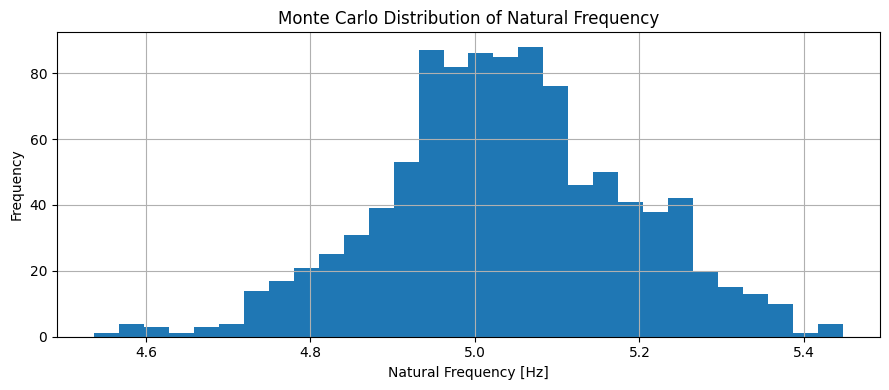

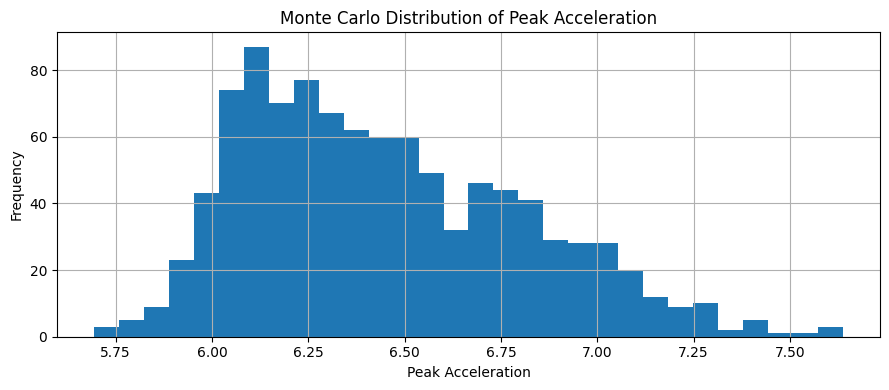

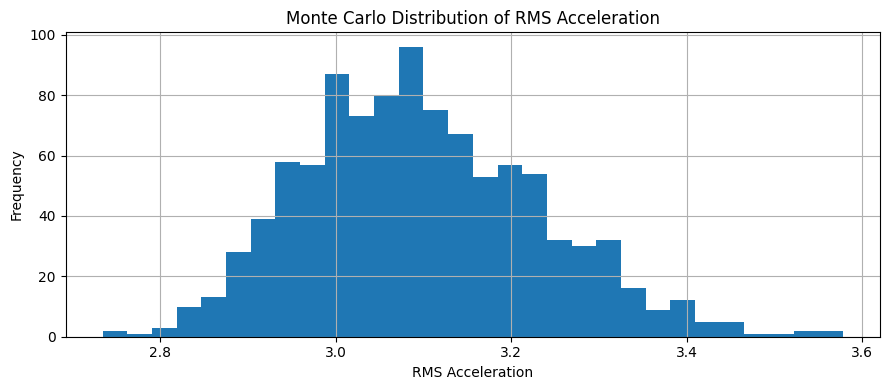

In [ ]:
# PLOT MONTE CARLO OUTPUT DISTRIBUTIONS

# Plot the distribution of the reference natural frequency.
plt.figure(figsize=(9, 4))

plt.hist(
    monte_carlo_results_data["natural_frequency"],
    bins=30,
)

plt.xlabel("Natural Frequency [Hz]")
plt.ylabel("Frequency")
plt.title("Monte Carlo Distribution of Natural Frequency")
plt.grid(True)
plt.tight_layout()
plt.show()


# Plot the distribution of peak acceleration.
plt.figure(figsize=(9, 4))

plt.hist(
    monte_carlo_results_data["peak_acceleration"],
    bins=30,
)

plt.xlabel("Peak Acceleration")
plt.ylabel("Frequency")
plt.title("Monte Carlo Distribution of Peak Acceleration")
plt.grid(True)
plt.tight_layout()
plt.show()


# Plot the distribution of RMS acceleration.
plt.figure(figsize=(9, 4))

plt.hist(
    monte_carlo_results_data["rms_acceleration"],
    bins=30,
)

plt.xlabel("RMS Acceleration")
plt.ylabel("Frequency")
plt.title("Monte Carlo Distribution of RMS Acceleration")
plt.grid(True)
plt.tight_layout()
plt.show()

## Monte Carlo Output Distributions

The Monte Carlo histograms show how uncertainty in the physical and measurement parameters propagates into distributions of the system-level response quantities.

The reference natural frequency is concentrated around approximately $5$ Hz and exhibits an approximately bell-shaped distribution. This is consistent with the bounded normally distributed uncertainty introduced in the mass and stiffness parameters.

The peak-acceleration distribution shows a less symmetric shape and a noticeable upper tail. This demonstrates that uncertainty in the input parameters does not necessarily propagate linearly into the dynamical response. The transient excitation, resonance behaviour, and nonlinear stiffness can transform relatively regular input distributions into more complex output distributions.

The RMS acceleration is concentrated primarily around $3.0$--$3.2$, with a smaller upper tail. Unlike peak acceleration, which represents the largest instantaneous response, RMS acceleration characterizes the overall magnitude of the acceleration signal throughout the simulation.

These distributions demonstrate that Monte Carlo simulation provides information that cannot be obtained from a single deterministic simulation or from mean values alone.

In [ ]:
# CALCULATE MONTE CARLO CONVERGENCE STATISTICS

# Read the sample sizes specified in the configuration.
convergence_sample_sizes = (
    monte_carlo_settings[
        "convergence_check"
    ]["sample_sizes"]
)


# We will examine convergence using two important outputs:
#
# 1. natural frequency
# 2. peak acceleration
#
# For each Monte Carlo sample size, we calculate the
# estimated mean and standard deviation.

convergence_results = []


for sample_size in convergence_sample_sizes:

    # Use only the first N Monte Carlo simulations.
    current_subset = (
        monte_carlo_results_data.iloc[
            :sample_size
        ]
    )


    # Natural-frequency statistics.
    natural_frequency_mean = (
        current_subset[
            "natural_frequency"
        ].mean()
    )

    natural_frequency_std = (
        current_subset[
            "natural_frequency"
        ].std()
    )


    # Peak-acceleration statistics.
    peak_acceleration_mean = (
        current_subset[
            "peak_acceleration"
        ].mean()
    )

    peak_acceleration_std = (
        current_subset[
            "peak_acceleration"
        ].std()
    )


    # Store the convergence results.
    convergence_results.append(
        {
            "sample_size": sample_size,

            "natural_frequency_mean":
                natural_frequency_mean,

            "natural_frequency_std":
                natural_frequency_std,

            "peak_acceleration_mean":
                peak_acceleration_mean,

            "peak_acceleration_std":
                peak_acceleration_std,
        }
    )


# Convert the convergence results into a DataFrame.
convergence_data = pd.DataFrame(
    convergence_results
)


convergence_data

,sample_size,natural_frequency_mean,natural_frequency_std,peak_acceleration_mean,peak_acceleration_std
0,100,5.024512,0.140872,6.432254,0.348301
1,250,5.040767,0.146219,6.452649,0.369241
2,500,5.041629,0.145861,6.465726,0.359763
3,1000,5.035831,0.148739,6.446664,0.359790


## Monte Carlo Convergence

The convergence analysis was performed using Monte Carlo sample sizes of

$$
N = 100,\ 250,\ 500,\ 1000.
$$

For the reference natural frequency, the estimated mean changed from approximately

$$
5.0245\ \text{Hz}
$$

at $N=100$ to

$$
5.0358\ \text{Hz}
$$

at $N=1000$.

The corresponding standard deviation changed from approximately

$$
0.1409\ \text{Hz}
$$

to

$$
0.1487\ \text{Hz}.
$$

For peak acceleration, the estimated mean changed from approximately

$$
6.4323
$$

at $N=100$ to

$$
6.4467
$$

at $N=1000$.

The peak-acceleration standard deviation changed from approximately

$$
0.3483
$$

to

$$
0.3598.
$$

The estimates fluctuate as additional Monte Carlo samples are included, but the changes remain relatively small at the larger sample sizes. This indicates that the main ensemble statistics are becoming stable and supports the use of $1000$ simulations for the present study.

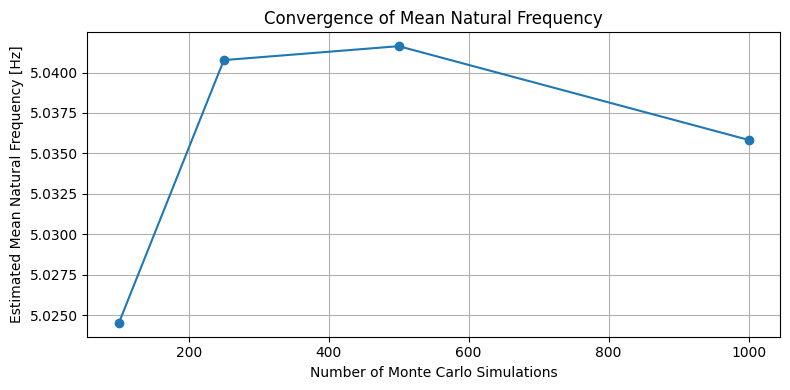

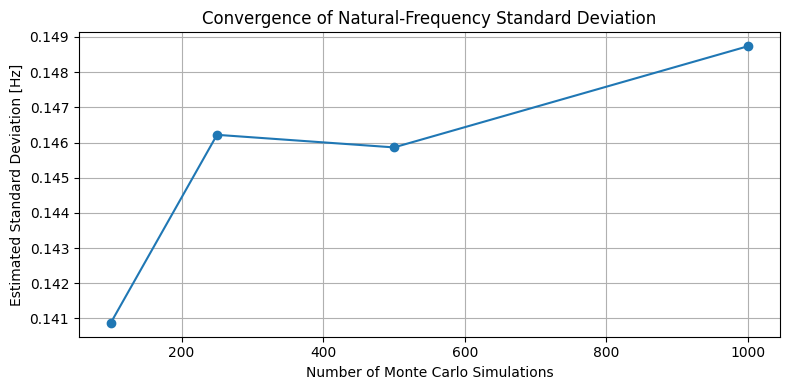

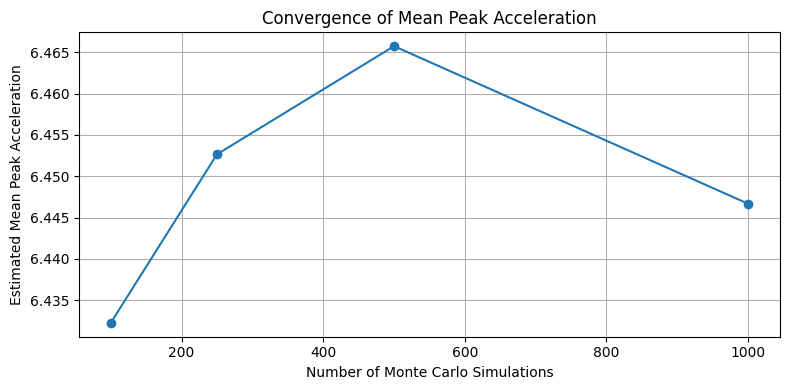

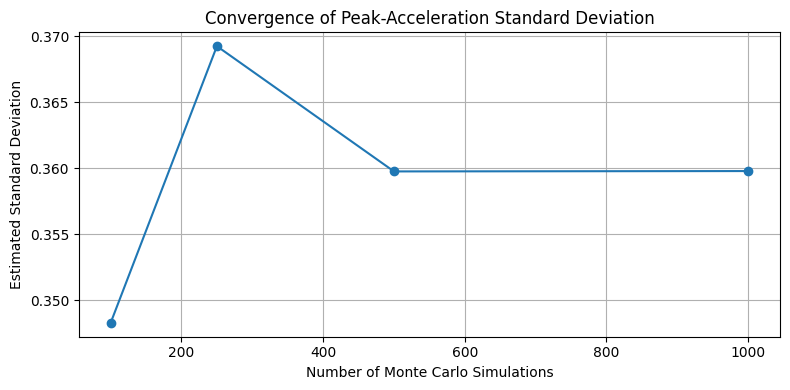

In [ ]:
# PLOT MONTE CARLO CONVERGENCE

# Plot convergence of the estimated mean natural frequency.
plt.figure(figsize=(8, 4))

plt.plot(
    convergence_data["sample_size"],
    convergence_data["natural_frequency_mean"],
    marker="o",
)

plt.xlabel("Number of Monte Carlo Simulations")
plt.ylabel("Estimated Mean Natural Frequency [Hz]")
plt.title("Convergence of Mean Natural Frequency")
plt.grid(True)
plt.tight_layout()
plt.show()


# Plot convergence of the natural-frequency standard deviation.
plt.figure(figsize=(8, 4))

plt.plot(
    convergence_data["sample_size"],
    convergence_data["natural_frequency_std"],
    marker="o",
)

plt.xlabel("Number of Monte Carlo Simulations")
plt.ylabel("Estimated Standard Deviation [Hz]")
plt.title("Convergence of Natural-Frequency Standard Deviation")
plt.grid(True)
plt.tight_layout()
plt.show()


# Plot convergence of the estimated mean peak acceleration.
plt.figure(figsize=(8, 4))

plt.plot(
    convergence_data["sample_size"],
    convergence_data["peak_acceleration_mean"],
    marker="o",
)

plt.xlabel("Number of Monte Carlo Simulations")
plt.ylabel("Estimated Mean Peak Acceleration")
plt.title("Convergence of Mean Peak Acceleration")
plt.grid(True)
plt.tight_layout()
plt.show()


# Plot convergence of the peak-acceleration standard deviation.
plt.figure(figsize=(8, 4))

plt.plot(
    convergence_data["sample_size"],
    convergence_data["peak_acceleration_std"],
    marker="o",
)

plt.xlabel("Number of Monte Carlo Simulations")
plt.ylabel("Estimated Standard Deviation")
plt.title("Convergence of Peak-Acceleration Standard Deviation")
plt.grid(True)
plt.tight_layout()
plt.show()

### Interpretation of the Convergence Results

The convergence plots show how the estimated Monte Carlo statistics change as the number of simulations increases from

$$
N=100
$$

to

$$
N=1000.
$$

The estimated mean natural frequency and mean peak acceleration show larger changes at smaller sample sizes and smaller relative changes as more simulations are included.

The estimated standard deviations show a similar pattern. In particular, the peak-acceleration standard deviation is almost unchanged between $N=500$ and $N=1000$.

The results therefore indicate that the main ensemble statistics are reasonably stable at the largest sample sizes considered. Although the estimates do not become perfectly constant, the remaining variation is small relative to the magnitude of the quantities being estimated.

For the present study, $1000$ Monte Carlo simulations are therefore considered sufficient for the initial uncertainty-propagation analysis.

In [ ]:
# SAVE MONTE CARLO ANALYSIS TABLES


# Create the results directory for Monte Carlo uncertainty analysis.
monte_carlo_results_directory = results_path(
    "monte_carlo_uq"
)

ensure_directory(
    monte_carlo_results_directory
)



# SAVE DESCRIPTIVE STATISTICS

descriptive_statistics_path = (
    monte_carlo_results_directory
    / "monte_carlo_descriptive_statistics.csv"
)

monte_carlo_descriptive_statistics.to_csv(
    descriptive_statistics_path
)



# SAVE CONVERGENCE RESULTS

convergence_results_path = (
    monte_carlo_results_directory
    / "monte_carlo_convergence.csv"
)

convergence_data.to_csv(
    convergence_results_path,
    index=False
)


print("Saved descriptive statistics to:")
print(descriptive_statistics_path)

print()

print("Saved convergence results to:")
print(convergence_results_path)

Saved descriptive statistics to:
D:\Uni\Mechanical Enginnering Masters\Extra\Data Analysis and Info Engineering\Part II Information Engineering\monte_carlo_mems_sciml\results\monte_carlo_uq\monte_carlo_descriptive_statistics.csv

Saved convergence results to:
D:\Uni\Mechanical Enginnering Masters\Extra\Data Analysis and Info Engineering\Part II Information Engineering\monte_carlo_mems_sciml\results\monte_carlo_uq\monte_carlo_convergence.csv


In [ ]:
# SAVE MONTE CARLO UNCERTAINTY FIGURES

# Use the existing uncertainty figure directory.
uncertainty_figure_directory = figures_path(
    "uncertainty"
)

ensure_directory(
    uncertainty_figure_directory
)



# 1. NATURAL-FREQUENCY DISTRIBUTION

plt.figure(figsize=(9, 4))

plt.hist(
    monte_carlo_results_data["natural_frequency"],
    bins=30,
)

plt.xlabel("Natural Frequency [Hz]")
plt.ylabel("Frequency")
plt.title("Monte Carlo Distribution of Natural Frequency")
plt.grid(True)
plt.tight_layout()

plt.savefig(
    uncertainty_figure_directory
    / "natural_frequency_distribution.png",
    dpi=300,
)

plt.close()



# 2. PEAK-ACCELERATION DISTRIBUTION

plt.figure(figsize=(9, 4))

plt.hist(
    monte_carlo_results_data["peak_acceleration"],
    bins=30,
)

plt.xlabel("Peak Acceleration")
plt.ylabel("Frequency")
plt.title("Monte Carlo Distribution of Peak Acceleration")
plt.grid(True)
plt.tight_layout()

plt.savefig(
    uncertainty_figure_directory
    / "peak_acceleration_distribution.png",
    dpi=300,
)

plt.close()



# 3. RMS-ACCELERATION DISTRIBUTION

plt.figure(figsize=(9, 4))

plt.hist(
    monte_carlo_results_data["rms_acceleration"],
    bins=30,
)

plt.xlabel("RMS Acceleration")
plt.ylabel("Frequency")
plt.title("Monte Carlo Distribution of RMS Acceleration")
plt.grid(True)
plt.tight_layout()

plt.savefig(
    uncertainty_figure_directory
    / "rms_acceleration_distribution.png",
    dpi=300,
)

plt.close()



# 4. CONVERGENCE OF MEAN NATURAL FREQUENCY

plt.figure(figsize=(8, 4))

plt.plot(
    convergence_data["sample_size"],
    convergence_data["natural_frequency_mean"],
    marker="o",
)

plt.xlabel("Number of Monte Carlo Simulations")
plt.ylabel("Estimated Mean Natural Frequency [Hz]")
plt.title("Convergence of Mean Natural Frequency")
plt.grid(True)
plt.tight_layout()

plt.savefig(
    uncertainty_figure_directory
    / "convergence_mean_natural_frequency.png",
    dpi=300,
)

plt.close()



# 5. CONVERGENCE OF NATURAL-FREQUENCY STANDARD DEVIATION
plt.figure(figsize=(8, 4))

plt.plot(
    convergence_data["sample_size"],
    convergence_data["natural_frequency_std"],
    marker="o",
)

plt.xlabel("Number of Monte Carlo Simulations")
plt.ylabel("Estimated Standard Deviation [Hz]")
plt.title(
    "Convergence of Natural-Frequency Standard Deviation"
)
plt.grid(True)
plt.tight_layout()

plt.savefig(
    uncertainty_figure_directory
    / "convergence_natural_frequency_std.png",
    dpi=300,
)

plt.close()



# 6. CONVERGENCE OF MEAN PEAK ACCELERATION
plt.figure(figsize=(8, 4))

plt.plot(
    convergence_data["sample_size"],
    convergence_data["peak_acceleration_mean"],
    marker="o",
)

plt.xlabel("Number of Monte Carlo Simulations")
plt.ylabel("Estimated Mean Peak Acceleration")
plt.title("Convergence of Mean Peak Acceleration")
plt.grid(True)
plt.tight_layout()

plt.savefig(
    uncertainty_figure_directory
    / "convergence_mean_peak_acceleration.png",
    dpi=300,
)

plt.close()



# 7. CONVERGENCE OF PEAK-ACCELERATION STANDARD DEVIATION

plt.figure(figsize=(8, 4))

plt.plot(
    convergence_data["sample_size"],
    convergence_data["peak_acceleration_std"],
    marker="o",
)

plt.xlabel("Number of Monte Carlo Simulations")
plt.ylabel("Estimated Standard Deviation")
plt.title(
    "Convergence of Peak-Acceleration Standard Deviation"
)
plt.grid(True)
plt.tight_layout()

plt.savefig(
    uncertainty_figure_directory
    / "convergence_peak_acceleration_std.png",
    dpi=300,
)

plt.close()


print("Monte Carlo uncertainty figures saved to:")
print(uncertainty_figure_directory)

Monte Carlo uncertainty figures saved to:
D:\Uni\Mechanical Enginnering Masters\Extra\Data Analysis and Info Engineering\Part II Information Engineering\monte_carlo_mems_sciml\figures\uncertainty


## Notebook 02 Summary

This notebook extended the deterministic MEMS model from Notebook 01 into a Monte Carlo uncertainty-analysis framework.

A total of

$$
N = 1000
$$

Monte Carlo parameter sets were generated using bounded normal and uniform probability distributions.

The uncertain quantities included physical, environmental, and measurement parameters:

- mass,
- damping,
- stiffness,
- nonlinear stiffness,
- temperature,
- measurement-noise standard deviation,
- sensor gain,
- sensor bias.

All generated samples satisfied their configured bounds and contained no missing values.

Each parameter set was then propagated through the MEMS dynamical simulation. Rather than storing all individual time series, compact response quantities were extracted for every simulation, including:

- reference natural frequency,
- damping ratio,
- peak displacement,
- peak velocity,
- peak acceleration,
- peak measured signal,
- RMS acceleration,
- RMS measured signal.

The resulting Monte Carlo dataset contains

$$
1000 \times 17
$$

values and was saved as

`data/monte_carlo/monte_carlo_results.csv`.

Across the ensemble, the mean reference natural frequency was

$$
\bar{f}_n = 5.035831\ \text{Hz},
$$

with a standard deviation of

$$
\sigma_{f_n} = 0.148739\ \text{Hz}.
$$

The mean peak acceleration was

$$
6.446664,
$$

with a standard deviation of

$$
0.359790.
$$

The Monte Carlo output distributions demonstrated that uncertainty in the model inputs propagates into measurable uncertainty in the dynamical response. In particular, the peak-acceleration distribution showed that relatively regular parameter distributions can lead to more complex response distributions.

A convergence study was performed using

$$
N = 100,\ 250,\ 500,\ 1000.
$$

The estimated means and standard deviations became relatively stable as the sample size increased. The peak-acceleration standard deviation was nearly unchanged between $N=500$ and $N=1000$, supporting the use of $1000$ simulations for the present uncertainty-propagation study.

The numerical Monte Carlo summaries were saved in

`results/monte_carlo_uq/`

and the corresponding uncertainty and convergence figures were saved in

`figures/uncertainty/`.

The Monte Carlo framework developed in this notebook provides the uncertainty-aware dataset required for the subsequent signal-processing, system-identification, equation-discovery, and machine-learning analyses.